In [3]:

%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



# Customer Segmentation Analysis Using K-Means Clustering

**Internship:** Oasis Infobyte Data Analytics

**Objective:** To group customers based on their purchasing behaviour using RFM analysis and the K-Means clustering algorithm.


In [4]:
print("Step 1: Python is working")

import os
print("Step 2: Current folder:", os.getcwd())

print("Step 3: Dataset exists:",
      os.path.exists("Dataset/Online Retail.xlsx"))

Step 1: Python is working
Step 2: Current folder: C:\Users\sanaa\OneDrive\Desktop\OIBSIP\Data Analytics-Task2-Customer-Segmentation
Step 3: Dataset exists: True


In [6]:

import pandas as pd

print("Loading dataset...")

df = pd.read_excel("Dataset/Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Loading dataset...
Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [7]:

import os
import pandas as pd

file_path = "Dataset/Online Retail.xlsx"

print("File size (MB):", round(os.path.getsize(file_path) / (1024 * 1024), 2))
print("Pandas version:", pd.__version__)
print("File exists:", os.path.isfile(file_path))


File size (MB): 22.62
Pandas version: 3.0.2
File exists: True


In [8]:

print("Testing Excel reader...")

import openpyxl

print("Openpyxl version:", openpyxl.__version__)

workbook = openpyxl.load_workbook(
    "Dataset/Online Retail.xlsx",
    read_only=True,
    data_only=True
)

print("Excel workbook opened!")
print("Sheet names:", workbook.sheetnames)

workbook.close()


Testing Excel reader...
Openpyxl version: 3.1.5
Excel workbook opened!
Sheet names: ['Online Retail']


In [9]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [13]:
import pandas as pd

print("Starting small read...")

df_test = pd.read_excel(
    "Dataset/Online Retail.xlsx",
    engine="openpyxl",
    nrows=5
)

print("Small read completed!")
display(df_test)

Starting small read...
Small read completed!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [14]:
df_test = pd.read_excel(
    "Dataset/Online Retail.xlsx",
    engine="openpyxl",
    nrows=5
)
display(df_test)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [15]:

print("Loading the full dataset. Please wait...")

df = pd.read_excel(
    "Dataset/Online Retail.xlsx",
    engine="openpyxl"
)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())


Loading the full dataset. Please wait...
Dataset loaded successfully!
Rows and columns: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [16]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe())


Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB

Missing values in each column:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Duplicate rows: 5268

Numerical summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [17]:

df_clean = df.copy()

# Convert columns to suitable data types
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)
df_clean["CustomerID"] = pd.to_numeric(
    df_clean["CustomerID"], errors="coerce"
)
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)
df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)

# Remove records missing essential information
df_clean = df_clean.dropna(
    subset=[
        "InvoiceNo", "InvoiceDate", "CustomerID",
        "Quantity", "UnitPrice"
    ]
)

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Exclude cancelled invoices
df_clean = df_clean[
    ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
]

# Exclude returns or invalid quantities and prices
df_clean = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0)
].copy()

# Calculate revenue
df_clean["Revenue"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Unique customers:", df_clean["CustomerID"].nunique())

display(df_clean.head())


Original rows: 541909
Cleaned rows: 392692
Rows removed: 149217
Unique customers: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


Top 10 countries by revenue:


,Total Revenue
Country,
United Kingdom,7285024.644
Netherlands,285446.340
EIRE,265262.460
Germany,228678.400
France,208934.310
Australia,138453.810
Spain,61558.560
Switzerland,56443.950
Belgium,41196.340


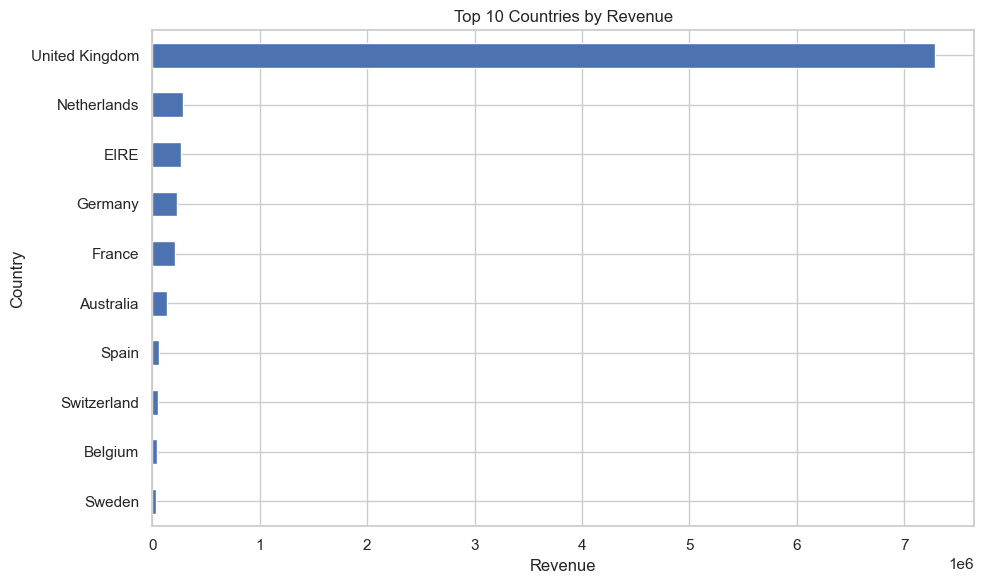

In [18]:

country_revenue = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 countries by revenue:")
display(country_revenue.to_frame("Total Revenue"))

plt.figure(figsize=(10, 6))
country_revenue.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


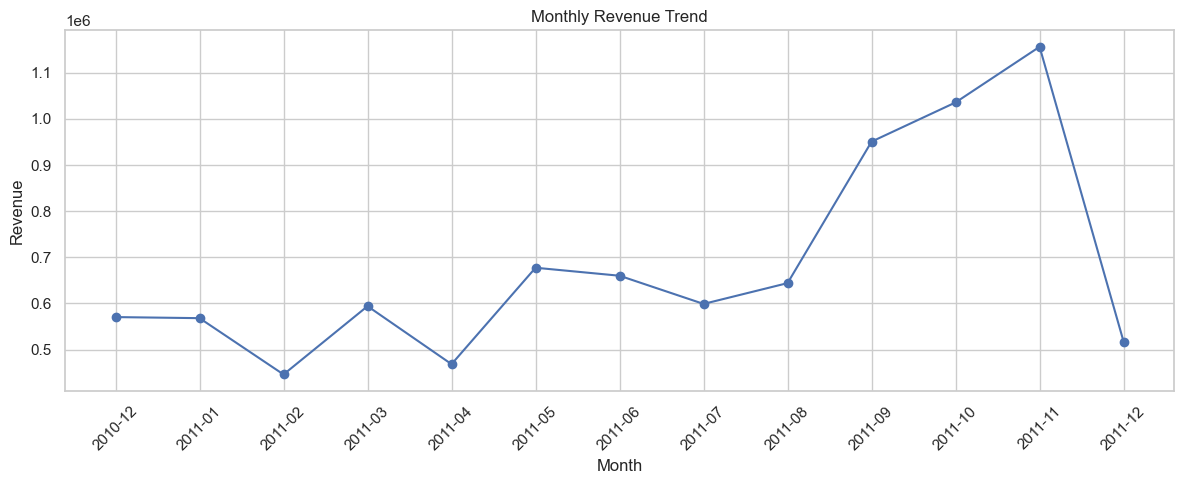

In [19]:

df_clean["YearMonth"] = (
    df_clean["InvoiceDate"].dt.to_period("M").astype(str)
)

monthly_revenue = (
    df_clean.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(monthly_revenue.index, monthly_revenue.values, marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [20]:

reference_date = (
    df_clean["InvoiceDate"].max().normalize()
    + pd.Timedelta(days=1)
)

rfm = df_clean.groupby("CustomerID").agg(
    Recency=(
        "InvoiceDate",
        lambda dates: (
            reference_date - dates.max().normalize()
        ).days
    ),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("RFM table created!")
print("Number of customers:", len(rfm))
display(rfm.head(10))


RFM table created!
Number of customers: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,3,7,4310.00
2,12348,76,4,1797.24
3,12349,19,1,1757.55
4,12350,311,1,334.40
5,12352,37,8,2506.04
6,12353,205,1,89.00
7,12354,233,1,1079.40
8,12355,215,1,459.40
9,12356,23,3,2811.43


In [21]:

# Check the RFM data
print("RFM dataset shape:", rfm.shape)

print("\nMissing values:")
print(rfm.isnull().sum())

print("\nSummary of RFM features:")
display(rfm[["Recency", "Frequency", "Monetary"]].describe())


RFM dataset shape: (4338, 4)

Missing values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

Summary of RFM features:


,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,93.059474,4.272015,2048.688081
std,100.012264,7.697998,8985.230220
min,1.000000,1.000000,3.750000
25%,18.000000,1.000000,306.482500
50%,51.000000,2.000000,668.570000
75%,142.750000,5.000000,1660.597500
max,374.000000,209.000000,280206.020000


In [22]:

# Select RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Reduce skewness in Frequency and Monetary values
rfm_features["Frequency"] = np.log1p(rfm_features["Frequency"])
rfm_features["Monetary"] = np.log1p(rfm_features["Monetary"])

# Standardize the features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

print("RFM features prepared successfully!")
print("Scaled data shape:", rfm_scaled.shape)
print("Number of features:", rfm_scaled.shape[1])


RFM features prepared successfully!
Scaled data shape: (4338, 3)
Number of features: 3


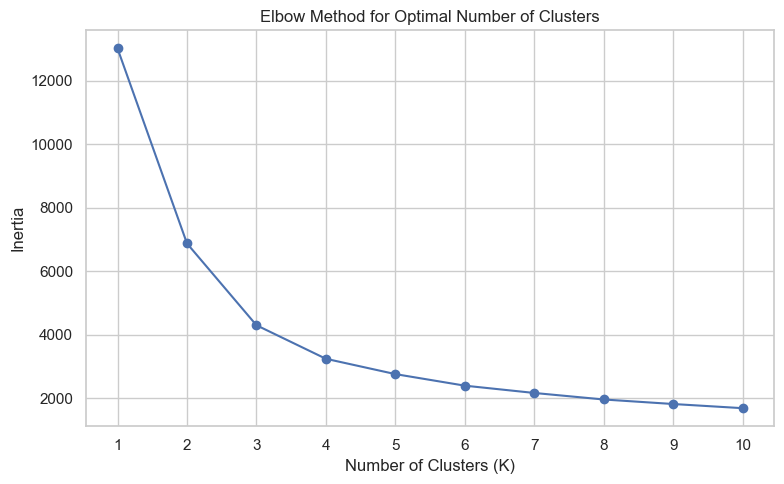

In [23]:

# Find the optimal number of clusters
inertia_values = []
k_values = range(1, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(rfm_scaled)
    inertia_values.append(model.inertia_)

# Plot the Elbow curve
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()


In [24]:

# Apply K-Means clustering
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# Assign a cluster to each customer
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("K-Means clustering completed successfully!")

print("\nNumber of customers in each cluster:")
display(rfm["Cluster"].value_counts().sort_index().to_frame("Customer Count"))


K-Means clustering completed successfully!

Number of customers in each cluster:


,Customer Count
Cluster,
0,1377
1,573
2,938
3,1450


In [25]:

# Summarize customer behavior in each cluster
cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Avg_Recency=("Recency", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean")
).round(2)

print("Customer Cluster Profiles:")
display(cluster_profile)


Customer Cluster Profiles:


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,1377,58.60,1.51,384.22
1,573,20.32,15.81,9799.78
2,938,259.92,1.37,385.39
3,1450,46.58,4.21,1642.33


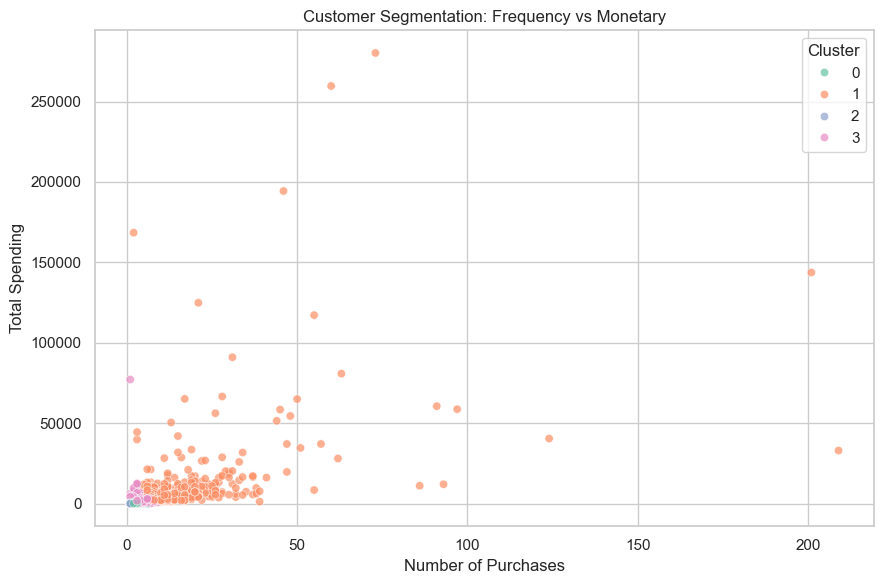

In [26]:

# Visualization 1: Frequency vs Monetary
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.title("Customer Segmentation: Frequency vs Monetary")
plt.xlabel("Number of Purchases")
plt.ylabel("Total Spending")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


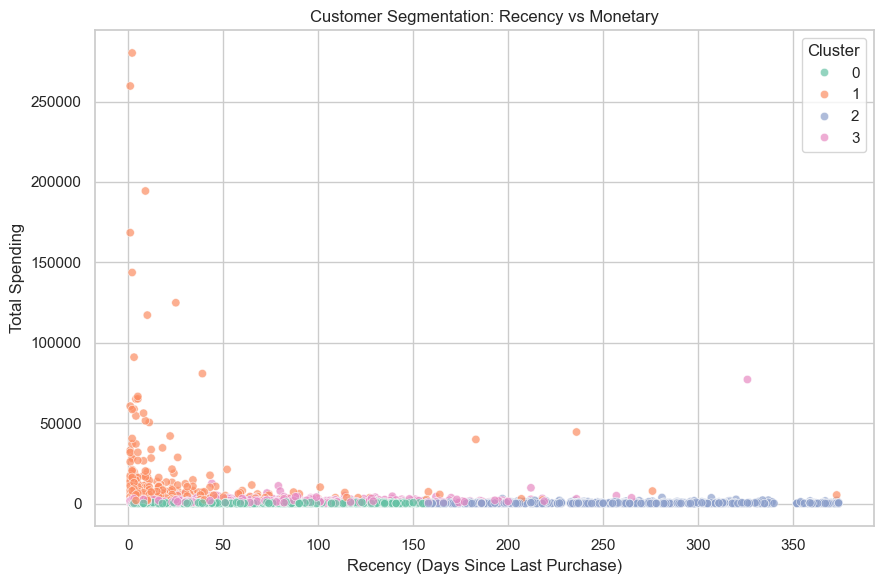

In [27]:

# Visualization 2: Recency vs Monetary
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Cluster",
    palette="Set2",
    alpha=0.7
)

plt.title("Customer Segmentation: Recency vs Monetary")
plt.xlabel("Recency (Days Since Last Purchase)")
plt.ylabel("Total Spending")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()


In [28]:

# Save customer segmentation results
output_file = "customer_segmentation_results.csv"

rfm.to_csv(output_file, index=False)

print("Customer segmentation results saved successfully!")
print("File location:", os.path.abspath(output_file))
print("Total customers saved:", len(rfm))

display(rfm.head(10))


Customer segmentation results saved successfully!
File location: C:\Users\sanaa\OneDrive\Desktop\OIBSIP\Data Analytics-Task2-Customer-Segmentation\customer_segmentation_results.csv
Total customers saved: 4338


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346,326,1,77183.60,3
1,12347,3,7,4310.00,1
2,12348,76,4,1797.24,3
3,12349,19,1,1757.55,3
4,12350,311,1,334.40,2
5,12352,37,8,2506.04,1
6,12353,205,1,89.00,2
7,12354,233,1,1079.40,2
8,12355,215,1,459.40,2
9,12356,23,3,2811.43,3


In [29]:

# Final project summary
print("=" * 50)
print("CUSTOMER SEGMENTATION ANALYSIS - FINAL SUMMARY")
print("=" * 50)

print("Total customers analyzed:", len(rfm))
print("Number of clusters:", rfm["Cluster"].nunique())
print("Total customer spending:", round(rfm["Monetary"].sum(), 2))

print("\nCustomers in each cluster:")
display(rfm["Cluster"].value_counts().sort_index().to_frame("Customer Count"))

print("\nCluster profiles:")
display(cluster_profile)

print("\nProject completed successfully!")


CUSTOMER SEGMENTATION ANALYSIS - FINAL SUMMARY
Total customers analyzed: 4338
Number of clusters: 4
Total customer spending: 8887208.89

Customers in each cluster:


,Customer Count
Cluster,
0,1377
1,573
2,938
3,1450



Cluster profiles:


,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary
Cluster,,,,
0,1377,58.60,1.51,384.22
1,573,20.32,15.81,9799.78
2,938,259.92,1.37,385.39
3,1450,46.58,4.21,1642.33



Project completed successfully!
